# Business Problem Understanding

In [1]:
# Assistant
# =============================================================================
# PROJECT : USED CAR PRICE PREDICTION
# =============================================================================

"""
Business Problem

Develop a Machine Learning Regression model that predicts the selling price
of a used car using the available vehicle features:

Target Variable:
    Price

Success Criteria:
    Train R2 Score >= 0.85
    Test R2 Score >= 0.85

"""

# =============================================================================
# IMPORT LIBRARIES
# =============================================================================

'\nBusiness Problem\n\nDevelop a Machine Learning Regression model that predicts the selling price\nof a used car using the available vehicle features:\n\nTarget Variable:\n    Price\n\nSuccess Criteria:\n    Train R2 Score >= 0.85\n    Test R2 Score >= 0.85\n\n'

In [2]:
import pandas as pd
import numpy as mp
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr

from scipy import stats
from datetime import datetime

wr.filterwarnings('ignore')
                  

# Load Dataset


In [3]:
# Load Dataset
df = pd.read_csv(r"C:\Users\Dell\Downloads\cars_data.xlsx.csv")

# Display Shape
df.shape

(32158, 12)

In [4]:
df.head()

,Name,Price,Rating,city,Kilometers,Year_of_Purchase,Owner,Fuel_Type,Transmission,RTO,Insurance,Insurance_Type
0,2010 Maruti Alto LXI,"₹ 174,699",4out of 5,3686,"Kilometers34,854 km",Year of PurchaseMay 2010,OwnerFirst Owner,FuelPetrol,TransmissionMANUAL,RTOAP09,NaN,Insurance TypeInsurance Expired
1,2013 Maruti Wagon R 1.0 VXI,"₹ 333,999",4.2out of 5,3686,"Kilometers39,541 km",Year of PurchaseJuly 2013,OwnerSecond Owner,FuelPetrol,TransmissionMANUAL,RTOAP28,Insurance6/8/2021,Insurance TypeComp
2,2014 Maruti Wagon R 1.0 VXI,"₹ 353,199",4.3out of 5,3686,"Kilometers23,233 km",Year of PurchaseMarch 2014,OwnerSecond Owner,FuelPetrol,TransmissionMANUAL,RTOAP28,Insurance28/4/2021,Insurance TypeComp
3,2013 Hyundai Eon D LITE PLUS,"₹ 237,899",4.4out of 5,3686,"Kilometers27,748 km",Year of PurchaseNovember 2013,OwnerFirst Owner,FuelPetrol,TransmissionMANUAL,RTOAP13,Insurance1/1/2022,Insurance TypeComp
4,2017 Hyundai Eon ERA PLUS,"₹ 300,699",4.4out of 5,3686,"Kilometers12,238 km",Year of PurchaseAugust 2017,OwnerSecond Owner,FuelPetrol,TransmissionMANUAL,RTOTS10,NaN,Insurance TypeExpired


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32158 entries, 0 to 32157
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Name              32158 non-null  object
 1   Price             32158 non-null  object
 2   Rating            32158 non-null  object
 3   city              32158 non-null  int64 
 4   Kilometers        32158 non-null  object
 5   Year_of_Purchase  32158 non-null  object
 6   Owner             32158 non-null  object
 7   Fuel_Type         32158 non-null  object
 8   Transmission      29342 non-null  object
 9   RTO               32158 non-null  object
 10  Insurance         22965 non-null  object
 11  Insurance_Type    32158 non-null  object
dtypes: int64(1), object(11)
memory usage: 2.9+ MB


# Data Type

In [6]:
df.dtypes

Name                object
Price               object
Rating              object
city                 int64
Kilometers          object
Year_of_Purchase    object
Owner               object
Fuel_Type           object
Transmission        object
RTO                 object
Insurance           object
Insurance_Type      object
dtype: object

In [7]:
# Null Value

In [8]:
df.isnull().sum()

Name                   0
Price                  0
Rating                 0
city                   0
Kilometers             0
Year_of_Purchase       0
Owner                  0
Fuel_Type              0
Transmission        2816
RTO                    0
Insurance           9193
Insurance_Type         0
dtype: int64

In [9]:
# Duplicate Record

In [10]:
df.duplicated().sum()

np.int64(0)

# Statistical Summary

In [11]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,32158,6885,2012 Mahindra XUV500 W8 FWD,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,32158,4822,"₹ 300,000",731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,32158,38,4.2out of 5,3050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,32158.0,NaN,NaN,NaN,2883.844207,1569.462476,290.0,1692.0,2423.0,4709.0,5732.0
Kilometers,32158,29089,"Kilometers100,000 km",39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Purchase,32158,343,Year of PurchaseJanuary 2012,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,32158,10,OwnerFirst Owner,19324,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fuel_Type,32158,6,FuelDiesel,15121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,29342,2,TransmissionMANUAL,26620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RTO,32158,777,RTOGJ01,2345,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df.columns

Index(['Name', 'Price', 'Rating', 'city', 'Kilometers', 'Year_of_Purchase',
       'Owner', 'Fuel_Type', 'Transmission', 'RTO', 'Insurance',
       'Insurance_Type'],
      dtype='object')

In [13]:
df.nunique().sort_values()

Transmission            2
Fuel_Type               6
Owner                  10
city                   10
Insurance_Type         12
Rating                 38
Year_of_Purchase      343
RTO                   777
Insurance             921
Price                4822
Name                 6885
Kilometers          29089
dtype: int64

# Data Cleaning

In [14]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing values in Transmission
df['Transmission'] = df['Transmission'].fillna(df['Transmission'].mode()[0])

In [15]:
df['Price'].head(10).tolist()

['₹ 174,699',
 '₹ 333,999',
 '₹ 353,199',
 '₹ 237,899',
 '₹ 300,699',
 '₹ 507,199',
 '₹ 188,147',
 '₹ 311,099',
 '₹ 607,099',
 '₹ 472,099']

In [16]:
# Clean Price
if df["Price"].dtype == "object":

    df["Price"] = df["Price"].str.replace("₹", "", regex=False)
    df["Price"] = df["Price"].str.replace(",", "", regex=False)

    df["Price"] = df["Price"].astype(float)

df["Price"] = df["Price"].round(2)

print([f"{x:.2f}" for x in df['Price'].head(10).tolist()])

['174699.00', '333999.00', '353199.00', '237899.00', '300699.00', '507199.00', '188147.00', '311099.00', '607099.00', '472099.00']


In [17]:
#Clean Rating
df['Rating'] = df['Rating'].astype(str).str.extract(r'(\d+\.?\d*)').astype(float)

print(df["Rating"].head())

0    4.0
1    4.2
2    4.3
3    4.4
4    4.4
Name: Rating, dtype: float64


In [18]:
# Clean Kilometers
df["Kilometers"] = df["Kilometers"].astype(str)

df["Kilometers"] = df["Kilometers"].str.replace("Kilometers", "", regex=False)
df["Kilometers"] = df["Kilometers"].str.replace("km", "", regex=False)
df["Kilometers"] = df["Kilometers"].str.replace(",", "", regex=False)

df["Kilometers"] = df["Kilometers"].astype(float)

pd.options.display.float_format = "{:.2f}".format

df["Kilometers"].head()

0   34854.00
1   39541.00
2   23233.00
3   27748.00
4   12238.00
Name: Kilometers, dtype: float64

In [19]:
#Clean Owner
df["Owner"] = df["Owner"].str.replace("Owner","")

df["Owner"] = df["Owner"].str.strip()

df["Owner"].head()

0     First
1    Second
2    Second
3     First
4    Second
Name: Owner, dtype: object

In [20]:
# Clean Fuel Type
df["Fuel_Type"] = df["Fuel_Type"].str.replace("Fuel","")

df["Fuel_Type"] = df["Fuel_Type"].str.strip()

df["Fuel_Type"].head()

0    Petrol
1    Petrol
2    Petrol
3    Petrol
4    Petrol
Name: Fuel_Type, dtype: object

In [21]:
#Clean Transmission
df["Transmission"] = df["Transmission"].str.replace("Transmission","")

df["Transmission"] = df["Transmission"].str.strip()

df["Transmission"].head()

0    MANUAL
1    MANUAL
2    MANUAL
3    MANUAL
4    MANUAL
Name: Transmission, dtype: object

In [22]:
#Clean Name
df["Name"] = df["Name"].str.strip()

df["Name"].head()

0            2010 Maruti Alto LXI
1     2013 Maruti Wagon R 1.0 VXI
2     2014 Maruti Wagon R 1.0 VXI
3    2013 Hyundai Eon D LITE PLUS
4       2017 Hyundai Eon ERA PLUS
Name: Name, dtype: object

In [23]:
# CLEAN YEAR OF PURCHASE COLUMN

df["Year_of_Purchase"] = df["Year_of_Purchase"].astype(str)
df["Year_of_Purchase"] = df["Year_of_Purchase"].str.replace(
    "Year of Purchase",
    "",
    regex=False
)

df["Year_of_Purchase"] = df["Year_of_Purchase"].str.strip()

# Convert Month and Year into Date
df["Year_of_Purchase"] = pd.to_datetime(
    df["Year_of_Purchase"],
    errors="coerce"
)

(df["Year_of_Purchase"].head())

#Extract Only the Year
df["Year_of_Purchase"] = df["Year_of_Purchase"].dt.year

print(df["Year_of_Purchase"].head())

0    2010
1    2013
2    2014
3    2013
4    2017
Name: Year_of_Purchase, dtype: int32


In [24]:
# CLEAN OWNER COLUMN

owner_map = {
    "First": 1,
    "Second": 2,
    "Third": 3,
    "Fourth": 4,
    "Fifth": 5,
    "Sixth": 6,
    "Seventh": 7,
    "Eighth": 8,
    "Ninth": 9,
    "Tenth": 10
}

df["Owner_Count"] = df["Owner"].replace(owner_map)

df["Owner_Count"] = df["Owner_Count"].astype(int)

print(df[["Owner","Owner_Count"]].head())

    Owner  Owner_Count
0   First            1
1  Second            2
2  Second            2
3   First            1
4  Second            2


In [25]:
# FEATURE EXTRACTION

# Extract Manufacture Year
df["Manufacture_Year"] = df["Name"].str[:4].astype(int)

# Extract Brand
df["Brand"] = df["Name"].str.split().str[1]

# Extract Car Model
df["Car_Model"] = df["Name"].str.split().str[2]

# Create Car Age
df["Car_Age"] = 2024 - df["Manufacture_Year"]

# Convert Car Age to Integer
df["Car_Age"] = df["Car_Age"].astype(int)

In [26]:
# Convert all Brand names into Title Case

df["Brand"] = df["Brand"].str.title()

print("Unique Brand Names")

print(df["Brand"].unique())

Unique Brand Names
['Maruti' 'Hyundai' 'Honda' 'Chevrolet' 'Ford' 'Renault' 'Volkswagen'
 'Tata' 'Mahindra' 'Toyota' 'Datsun' 'Mitsubishi' 'Nissan' 'Kia' 'Fiat'
 'Skoda' 'Opel' 'Mg' 'Volvo' 'Jeep' 'Mercedes' 'Ssangyong' 'Bmw' 'Audi'
 'Daewoo' 'Jaguar' 'Landrover' 'Force' 'Isuzu' 'Porsche' 'Premier'
 'Hindustan' 'Icml']


In [27]:
# Clean RTO
df["RTO"] = df["RTO"].str.replace("RTO", "", regex=False)
df["RTO"] = df["RTO"].str.strip().str.upper()

# Create State Code
df["RTO_State"] = df["RTO"].str[:2]

In [28]:
print(df[["RTO", "RTO_State"]].head(10))
df["RTO_State"].unique()

    RTO RTO_State
0  AP09        AP
1  AP28        AP
2  AP28        AP
3  AP13        AP
4  TS10        TS
5  AP09        AP
6  AP28        AP
7  AP11        AP
8  TS07        TS
9  TS10        TS


array(['AP', 'TS', 'DL', 'TN', 'MH', 'HR', 'UP', 'KA', 'WB', 'KL', 'OD',
       'RJ', 'JH', 'AH', 'OR', 'CH', 'GJ', 'UK', 'MP', 'PB', 'MJ', 'PY',
       'CG', 'AS', '0R', 'TE', 'HP', 'WD', 'TD', 'AN', 'CA', 'BR', 'ML',
       'K0', 'GA', 'CK', 'KS', 'JK', 'WN', 'WE', 'TR', 'WM', '0D', 'DD',
       'MG', 'DN', 'UA', 'UM', 'GH', 'GK', 'GU', 'AR', 'MN', 'PC'],
      dtype=object)

In [29]:
# CLEAN INSURANCE COLUMN

# Fill missing values
df["Insurance"] = df["Insurance"].fillna("No Insurance")

# Convert to string
df["Insurance"] = df["Insurance"].astype(str)

# Create Insurance_Year column by removing the word "Insurance"
df["Insurance_Year"] = df["Insurance"].str.replace(
    "Insurance ",
    "",
    regex=False
)

# Remove extra spaces
df["Insurance_Year"] = df["Insurance_Year"].str.strip()

In [30]:
# Convert to Date format (DD-MM-YYYY)
df["Insurance_Year"] = pd.to_datetime(
    df["Insurance_Year"],
    dayfirst=True,
    errors="coerce"
).dt.strftime("%d/%m/%Y")

# Replace missing dates with 00/00/0000
df["Insurance_Year"] = df["Insurance_Year"].fillna("0")

# Keep only Insurance / No Insurance
df.loc[df["Insurance"] != "No Insurance", "Insurance"] = "Insurance"

# Check Output
print(df[["Insurance", "Insurance_Year"]].head(10))

      Insurance Insurance_Year
0  No Insurance              0
1     Insurance              0
2     Insurance              0
3     Insurance              0
4  No Insurance              0
5     Insurance              0
6  No Insurance              0
7     Insurance              0
8  No Insurance              0
9     Insurance              0


In [31]:
print(df[
    [
        "Rating",
        "Kilometers",
        "Owner",
        "Fuel_Type",
        "Transmission",
        "Manufacture_Year",
        "Brand",
        "Car_Model",
        "Car_Age"
    ]
].head())

   Rating  Kilometers   Owner Fuel_Type Transmission  Manufacture_Year  \
0    4.00    34854.00   First    Petrol       MANUAL              2010   
1    4.20    39541.00  Second    Petrol       MANUAL              2013   
2    4.30    23233.00  Second    Petrol       MANUAL              2014   
3    4.40    27748.00   First    Petrol       MANUAL              2013   
4    4.40    12238.00  Second    Petrol       MANUAL              2017   

     Brand Car_Model  Car_Age  
0   Maruti      Alto       14  
1   Maruti     Wagon       11  
2   Maruti     Wagon       10  
3  Hyundai       Eon       11  
4  Hyundai       Eon        7  


In [32]:
# Automatic Transmission
import numpy as np
df["Transmission_Automatic"] = np.where(
    df["Transmission"] == "AUTOMATIC",
    1,
    0
)

In [33]:
#Insurance Available

df["Has_Insurance"] = np.where(
    df["Insurance"].isnull(),
    0,
    1
)

In [34]:
# Clean Insurance Type

# Convert to string
df["Insurance_Type"] = df["Insurance_Type"].astype(str)

# Remove 'Insurance Type' (handles extra spaces)
df["Insurance_Type"] = df["Insurance_Type"].str.replace(
    r"Insurance\s*Type",
    "",
    regex=True
)

# Remove extra spaces
df["Insurance_Type"] = df["Insurance_Type"].str.strip()

# Check output
print(df["Insurance_Type"].value_counts())

Insurance_Type
Comprehensive        6506
Insurance Expired    5426
Comp                 5295
Expired              3976
3rd Party            3642
Zero Depreciation    2884
Third_party          2648
Zero_Dep             1750
Not Available          24
Normal                  5
NA                      1
null                    1
Name: count, dtype: int64


In [35]:
# Replace Insurance Names

insurance_map = {
    "Comp": "Comprehensive",
    "Comprehensive": "Comprehensive",

    "Insurance Expired": "Expired",
    "Expired": "Expired",

    "3rd Party": "Third Party",
    "Third_party": "Third Party",

    "Zero_Dep": "Zero Depreciation",
    "Zero Depreciation": "Zero Depreciation",

    "Normal": "Not Available",
    "Not Available": "Not Available",

    "NA": "Not Available",
    "null": "Not Available"
}

df["Insurance_Type"] = df["Insurance_Type"].replace(insurance_map)

# Fill missing values
df["Insurance_Type"] = df["Insurance_Type"].fillna("Not Available")

# Check final output
print(df["Insurance_Type"].value_counts())

Insurance_Type
Comprehensive        11801
Expired               9402
Third Party           6290
Zero Depreciation     4634
Not Available           31
Name: count, dtype: int64


In [36]:
#Remove Invalid Records

# Price
df = df[(df['Price'] >= 10000) & (df['Price'] <= 3000000)]

# Kilometers
df = df[(df['Kilometers'] >= 100) & (df['Kilometers'] <= 400000)]

# Car Age
df = df[(df['Car_Age'] >= 0) & (df['Car_Age'] <= 30)]

# Rating
df = df[(df['Rating'] >= 1) & (df['Rating'] <= 5)]

In [37]:
# Remove Missing Values
df = df.dropna(subset=[
    'Price',
    'Rating',
    'Kilometers',
    'Manufacture_Year',
    'Owner_Count'
])

df.shape

(31910, 21)

In [38]:
# List of numeric columns
columns = ["Price", "Rating", "Kilometers", "Car_Age"]

# Check each column
for column in columns:

    # Calculate Q1 and Q3
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate Lower and Upper Limits
    Lower_Limit = Q1 - 1.5 * IQR
    Upper_Limit = Q3 + 1.5 * IQR

    # Count outliers
    Outliers = df[(df[column] < Lower_Limit) | (df[column] > Upper_Limit)]

    print("Lower Limit :", round(Lower_Limit, 2))
    print("Upper Limit :", round(Upper_Limit, 2))
    print(f"{column} Outliers : {Outliers.shape[0]}")
    print("Percentage :", round((Outliers.shape[0] / len(df)) * 100, 2), "%")

Lower Limit : -375000.0
Upper Limit : 1185000.0
Price Outliers : 1517
Percentage : 4.75 %
Lower Limit : 2.9
Upper Limit : 5.3
Rating Outliers : 757
Percentage : 2.37 %
Lower Limit : -55901.38
Upper Limit : 196137.62
Kilometers Outliers : 803
Percentage : 2.52 %
Lower Limit : -1.0
Upper Limit : 23.0
Car_Age Outliers : 475
Percentage : 1.49 %


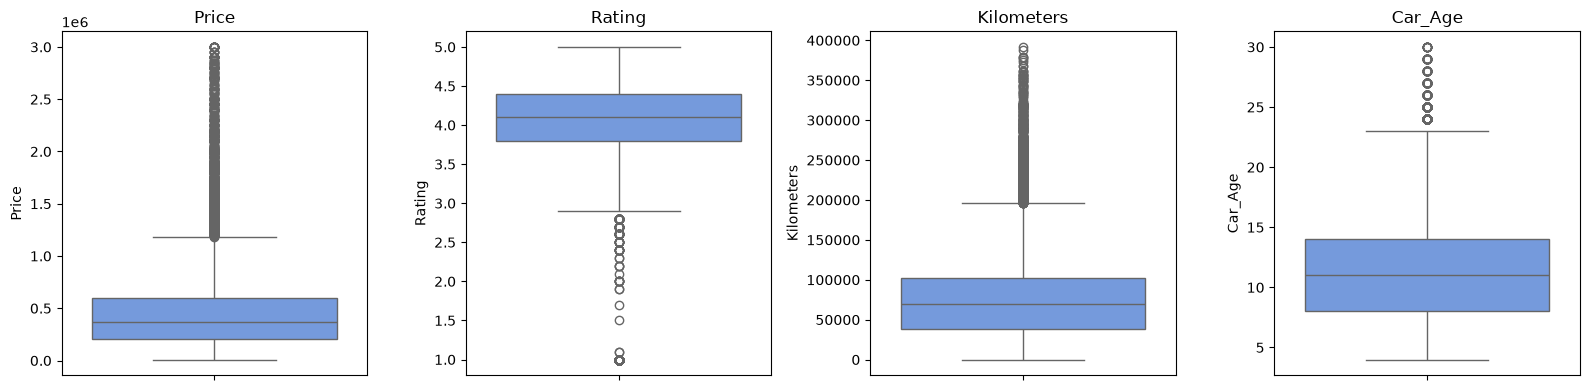

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, col in zip(axes, ['Price', 'Rating', 'Kilometers', 'Car_Age']):
    sns.boxplot(y=df[col], ax=ax, color='cornflowerblue')
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [40]:
# Check Cars with Very High Kilometers

high_km = df[df['Kilometers'] > 196000]

high_km[['Name', 'Kilometers', 'Car_Age', 'Price']].sort_values(
    'Kilometers',
    ascending=False
)

,Name,Kilometers,Car_Age,Price
7730,2011 Tata Indica V2 LS,391710.00,13,120000.00
4782,2010 Mahindra Scorpio SLE BS IV,387825.00,14,402000.00
18097,2015 Mahindra Scorpio S4,379447.00,9,653000.00
7972,2009 Toyota Innova 2.5 G4 7 STR,379012.00,15,550000.00
4042,2013 Tata Indica Vista LS TDI BS III,377433.00,11,144000.00
...,...,...,...,...
27826,2007 Mahindra Renault Logan DLS 1.5 DCI,196318.00,17,60000.00
4305,2009 Toyota Innova 2.5 G4 8 STR,196266.00,15,500000.00
31988,2013 Toyota Etios Liva GD,196176.00,11,350000.00
18281,2012 Maruti Ritz VDI,196032.00,12,320000.00


In [41]:
# Check Suspicious Records

# Find cars that are more than 10 years old
# but have less than 500 kilometers

suspicious = df[(df["Car_Age"] > 10) & (df["Kilometers"] < 500)]

# Count suspicious records
print("Number of Suspicious Cars :", len(suspicious))

print(suspicious[["Name", "Kilometers", "Car_Age", "Price"]])

Number of Suspicious Cars : 10
                                          Name  Kilometers  Car_Age     Price
5984                      2009 Maruti Ritz LXI      394.00       15 220000.00
13437             2009 Chevrolet Aveo U VA 1.2      123.00       15  50297.00
13688            2004 Hyundai Accent VIVA CRDI      123.00       20  40000.00
15001          2000 Mitsubishi Lancer SFXI 1.5      111.00       24  50000.00
19167            2010 Chevrolet Beat LT PETROL      111.00       14  40000.00
19496            2011 Hyundai i20 SPORTZ 1.2 O      356.00       13 259667.00
20141              2011 Fiat Linea EMOTION 1.3      100.00       13 200000.00
20509  2007 Mahindra Renault Logan DLS 1.5 DCI      100.00       17  66000.00
25675               1999 Honda City 1.5 EXI AT      136.00       25  75000.00
30627                 2007 Ford Ikon 1.3 FLAIR      462.00       17  35400.00


In [42]:
# Remove Suspicious Records
# Count rows before removing records
before = df.shape[0]

# Remove cars older than 10 years with less than 500 km
df = df[~((df["Car_Age"] > 10) & (df["Kilometers"] < 500))]

# Count rows after removing records
after = df.shape[0]

# Display number of rows removed
print("Rows Removed :", before - after)

# Display remaining rows
print("Remaining Rows :", after)


# ===================================
# Convert Data Types
# ===================================

# Convert Manufacture_Year to Integer
df["Manufacture_Year"] = df["Manufacture_Year"].astype(int)

# Convert Car_Age to Integer
df["Car_Age"] = df["Car_Age"].astype(int)

df.shape

Rows Removed : 10
Remaining Rows : 31900


(31900, 21)

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df["RTO"].astype(str).str.contains("RTO").any()

np.False_

In [45]:
df["RTO_State"].astype(str).str.isupper().all()

np.True_

In [46]:
df["Name"] == df["Name"].str.strip().all()

0        False
1        False
2        False
3        False
4        False
         ...  
32153    False
32154    False
32155    False
32156    False
32157    False
Name: Name, Length: 31900, dtype: bool

In [47]:
df["Insurance"].isnull().sum() == 0

np.True_

In [48]:
df["Insurance_Type"].isnull().sum() == 0

np.True_

In [49]:
df["Brand"].str.lower().nunique() == df["Brand"].nunique()

True

In [50]:
df.isnull().sum()

Name                      0
Price                     0
Rating                    0
city                      0
Kilometers                0
Year_of_Purchase          0
Owner                     0
Fuel_Type                 0
Transmission              0
RTO                       0
Insurance                 0
Insurance_Type            0
Owner_Count               0
Manufacture_Year          0
Brand                     0
Car_Model                 0
Car_Age                   0
RTO_State                 0
Insurance_Year            0
Transmission_Automatic    0
Has_Insurance             0
dtype: int64

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df.shape

(31900, 21)

In [53]:
df.dtypes

Name                       object
Price                     float64
Rating                    float64
city                        int64
Kilometers                float64
Year_of_Purchase            int32
Owner                      object
Fuel_Type                  object
Transmission               object
RTO                        object
Insurance                  object
Insurance_Type             object
Owner_Count                 int64
Manufacture_Year            int64
Brand                      object
Car_Model                  object
Car_Age                     int64
RTO_State                  object
Insurance_Year             object
Transmission_Automatic      int64
Has_Insurance               int64
dtype: object

In [54]:
print("Final Dataset Shape :", df.shape)

Final Dataset Shape : (31900, 21)


In [55]:
# Export Cleaned Data

df.to_csv(r"C:\Users\Dell\Downloads\cars24_cleaned.csv", index=False)

print("File Saved Successfully")


File Saved Successfully


In [56]:
# Clean Rating Column
df['Rating'] = df['Rating'].astype(str).str.extract(r'(\d+\.?\d*)').astype(float)

# Calculate Skewness
df[['Price', 'Rating', 'Kilometers', 'Car_Age']].skew()

Price         2.25
Rating       -2.35
Kilometers    1.23
Car_Age       0.73
dtype: float64

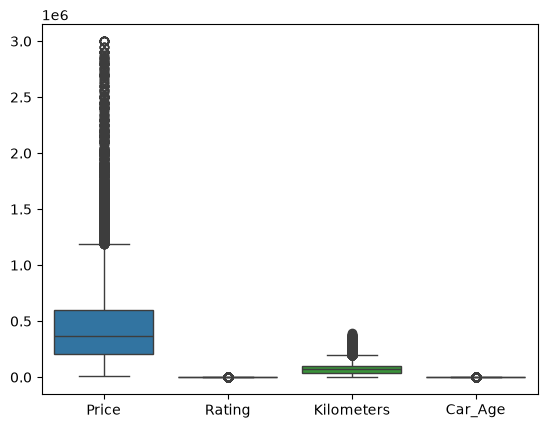

In [57]:
sns.boxplot(df[['Price', 'Rating', 'Kilometers', 'Car_Age']])
plt.show()

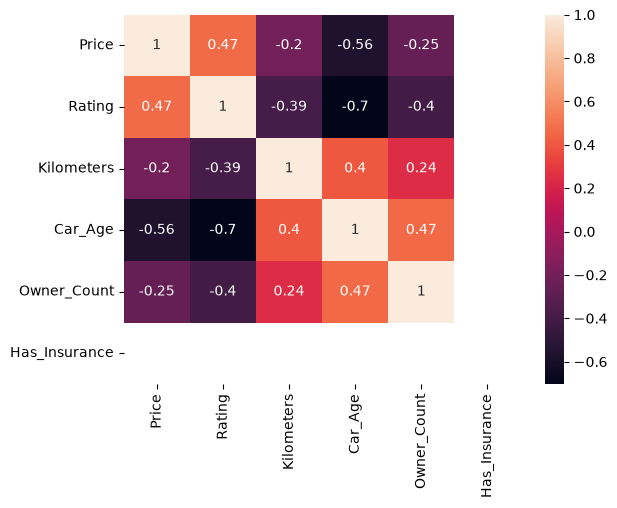

In [58]:
sns.heatmap(df[['Price', 'Rating', 'Kilometers', 'Car_Age', 'Owner_Count', 'Has_Insurance']].corr(), annot=True)
plt.show()

# Train-Test Split and Target Encoding

In [59]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, train_size=0.75, random_state=9)

te_cols = ['Fuel_Type', 'Brand', 'Car_Model', 'RTO_State', 'city', 'Insurance_Type']
global_mean = train_df['Price'].mean()

for c in te_cols:
    means = train_df.groupby(c)['Price'].mean()
    train_df[c + '_TE'] = train_df[c].map(means)
    test_df[c + '_TE'] = test_df[c].map(means).fillna(global_mean)

feature_cols = [
    'Rating', 'Kilometers', 'Car_Age', 'Owner_Count',
    'Has_Insurance', 'Transmission_Automatic',
    'Fuel_Type_TE', 'Brand_TE', 'Car_Model_TE',
    'RTO_State_TE', 'city_TE', 'Insurance_Type_TE'
]

x_train = train_df[feature_cols]
x_test = test_df[feature_cols]
y_train = train_df['Price']
y_test = test_df['Price']

In [60]:
x_train

,Rating,Kilometers,Car_Age,Owner_Count,Has_Insurance,Transmission_Automatic,Fuel_Type_TE,Brand_TE,Car_Model_TE,RTO_State_TE,city_TE,Insurance_Type_TE
25384,3.20,103482.00,20,2,1,0,251070.53,416128.47,123091.47,383099.15,379056.42,375972.31
15302,4.30,16551.00,7,1,1,0,373534.54,416128.47,423407.08,463486.82,444313.70,381877.23
29796,3.80,160450.00,12,1,1,0,584854.31,373387.27,380783.82,409922.84,406939.25,463633.80
10227,4.70,33921.00,8,1,1,0,373534.54,416128.47,240578.19,533070.71,514961.81,744391.76
5412,3.70,22676.00,15,1,1,0,373534.54,373387.27,202823.57,549035.92,546550.69,463633.80
...,...,...,...,...,...,...,...,...,...,...,...,...
22791,4.90,40762.00,7,1,1,0,373534.54,416128.47,628167.77,411441.29,416015.73,744391.76
507,4.20,61334.00,13,2,1,0,373534.54,373387.27,380783.82,330388.06,488453.20,381877.23
23379,4.30,103771.00,16,2,1,0,584854.31,373387.27,380783.82,411441.29,416015.73,375972.31
21013,4.30,69652.00,7,1,1,0,251070.53,373387.27,202823.57,463486.82,480556.88,463633.80


In [61]:
# 1. Clean Rating
df['Rating'] = pd.to_numeric(
    df['Rating'].astype(str).str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

from sklearn.preprocessing import StandardScaler
import pandas as pd

sc = StandardScaler()

x_train = pd.DataFrame(
    sc.fit_transform(x_train),
    columns=feature_cols,
    index=x_train.index
)

x_test = pd.DataFrame(
    sc.transform(x_test),
    columns=feature_cols,
    index=x_test.index
)

x_train.head()

,Rating,Kilometers,Car_Age,Owner_Count,Has_Insurance,Transmission_Automatic,Fuel_Type_TE,Brand_TE,Car_Model_TE,RTO_State_TE,city_TE,Insurance_Type_TE
25384,-1.41,0.55,1.90,0.53,0.00,-0.30,-1.76,-0.22,-1.11,-0.85,-1.64,-0.71
15302,0.41,-1.18,-1.04,-0.67,0.00,-0.30,-0.74,-0.22,-0.13,0.01,-0.36,-0.67
29796,-0.42,1.69,0.09,-0.67,0.00,-0.30,1.02,-0.41,-0.27,-0.56,-1.09,0.01
10227,1.08,-0.84,-0.81,-0.67,0.00,-0.30,-0.74,-0.22,-0.73,0.75,1.02,2.32
5412,-0.58,-1.06,0.77,-0.67,0.00,-0.30,-0.74,-0.41,-0.85,0.92,1.64,0.01


# Linear Regression

In [62]:
#Modeling
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

print('coefficient :', model.coef_)
print('intercept :', model.intercept_)

#Prediction
x_pred_train = model.predict(x_train)
x_pred_test = model.predict(x_test)

#Evolution
print('train_r2 :', model.score(x_train, y_train))
print('test_r2 :', model.score(x_test, y_test))

#CV_Score cross validation score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model, x_train, y_train, cv=5)
print('cv_score :', cv_score.mean())

coefficient : [  8281.94023026 -41376.64360196 -86927.22528074 -11881.85849087
      0.          33749.30180764  28223.70381376  59311.65721659
 196970.74738748  17319.99673773  18950.32955627  19985.00567852]
intercept : 462725.5164890283
train_r2 : 0.761456075259983
test_r2 : 0.7489836704957976
cv_score : 0.7610689159798313


In [63]:
#checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

cv_score = cross_val_score(
    model,
    x_train,
    y_train,
    cv=4,
    scoring='neg_mean_squared_error'
)

cv_score = abs(cv_score.mean())

print('cv_score :', cv_score**0.5)
print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

cv_score : 185695.06814527334
train_RMSE : 185534.92914288005
test_RMSE : 188790.95195696494


# Polynomial Regression

In [64]:
from sklearn.preprocessing import PolynomialFeatures

PC = PolynomialFeatures(degree=2, include_bias=False)

x_poly_train = PC.fit_transform(x_train)  #numpy array
x_poly_test = PC.transform(x_test)

from sklearn.linear_model import LinearRegression

model_p = LinearRegression()
model_p.fit(x_poly_train, y_train)

print('coefficient :', model_p.coef_)
print('intercept :', model_p.intercept_)

#Prediction
x_pred_train = model_p.predict(x_poly_train)
x_pred_test = model_p.predict(x_poly_test)

#Evolution
print('train_r2 :', model_p.score(x_poly_train, y_train))
print('test_r2 :', model_p.score(x_poly_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model_p, x_poly_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

coefficient : [ 6.08200248e+04 -1.43196121e+04 -1.21032368e+05 -9.50656475e+03
 -8.73114914e-11  2.55981860e+03  3.96868781e+04  1.06024449e+05
  1.62080311e+05  1.03870715e+04  2.34380444e+04  6.05603273e+03
  5.03015667e+03 -6.20831810e+03 -1.12565397e+03 -1.75817811e+02
 -1.27329258e-11  8.09081554e+02  3.65158655e+03  1.75614237e+04
  6.61762210e+03  5.39285318e+03  3.81542653e+03  1.01569005e+04
  4.26422356e+03 -8.13494034e+03  4.42833272e+03 -5.45696821e-12
  1.60957908e+03 -1.07994200e+04 -9.24762585e+03  3.40897538e+03
 -1.80617147e+03  3.16194207e+03 -4.73426625e+01  6.56813143e+03
  1.88422560e+03 -2.91038305e-11 -2.90665787e+04 -8.23917931e+03
 -1.23342715e+04 -4.93530534e+04  5.37841231e+03  1.71324384e+03
  7.73563687e+03  2.13173815e+02 -2.91038305e-11 -3.90291011e+02
 -2.12397857e+02 -1.01018269e+03 -8.02041911e+03 -2.08032818e+03
  3.28268201e+03  3.55558828e+03 -1.45519152e-11 -1.81898940e-12
  7.27595761e-12  4.54747351e-12  1.45519152e-11 -9.09494702e-13
  7.2759576

In [65]:
#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

cv_score = cross_val_score(
    model_p,
    x_poly_train,
    y_train,
    cv=4,
    scoring='neg_mean_squared_error'
)

cv_score = abs(cv_score.mean())

print('cv_score_RMSE :', cv_score**0.5)
print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

cv_score_RMSE : 157423.57650804118
train_RMSE : 156152.55285944938
test_RMSE : 160549.28181297096


# Lasso L1 Regression

In [66]:
from sklearn.linear_model import Lasso

model = Lasso(alpha=10)
model.fit(x_train, y_train)

print('coefficient :', model.coef_)
print('intercept :', model.intercept_)

#Prediction
x_pred_train = model.predict(x_train)
x_pred_test = model.predict(x_test)

#Evolution
print('train_r2 :', model.score(x_train, y_train))
print('test_r2 :', model.score(x_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model, x_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

coefficient : [  8280.28664183 -41364.65575335 -86930.62459378 -11875.15852207
      0.          33742.62113366  28210.56135418  59301.55314071
 196976.93441026  17316.41124719  18944.09420983  19979.13921768]
intercept : 462725.5164890283
train_r2 : 0.7614560713458218
test_r2 : 0.7489823472309218
cv_score : 0.7610840660596212


# Ridge L2 Regression

In [67]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=1)
model.fit(x_train, y_train)

print('coefficient :', model.coef_)
print('intercept :', model.intercept_)

#Prediction
x_pred_train = model.predict(x_train)
x_pred_test = model.predict(x_test)

#Evolution
print('train_r2 :', model.score(x_train, y_train))
print('test_r2 :', model.score(x_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model, x_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

cv_score = cross_val_score(
    model,
    x_train,
    y_train,
    cv=4,
    scoring='neg_mean_squared_error'
)

cv_score = abs(cv_score.mean())

print('cv_score_RMSE :', cv_score**0.5)
print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

coefficient : [  8288.0230712  -41374.7095591  -86924.24555476 -11882.44197753
      0.          33749.94079934  28226.18457627  59318.96366553
 196954.8885125   17321.3389636   18948.73857663  19986.54456708]
intercept : 462725.5164890283
train_r2 : 0.7614560744326699
test_r2 : 0.7489847724700762
cv_score : 0.7610840710031761
cv_score_RMSE : 185695.05795207282
train_RMSE : 185534.9294646143
test_RMSE : 188790.53755563524


# Ridge Hyperparameter Tuning

In [68]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

r = Ridge()

grid = GridSearchCV(
    estimator=r,
    param_grid={'alpha': range(1, 100)},
    cv=5
)

grid.fit(x_train, y_train)
print(grid.best_params_)

{'alpha': 12}


# Elastic Net Regression

In [69]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet

e = ElasticNet()

grid = GridSearchCV(
    estimator=e,
    param_grid={'alpha': range(1, 10), 'l1_ratio': [0.01, 0.1, 0.2, 0.5, 0.8, 1]},
    cv=5
)

grid.fit(x_train, y_train)
print(grid.best_params_)

{'alpha': 1, 'l1_ratio': 1}


In [70]:
from sklearn.linear_model import ElasticNet

model_en = ElasticNet(alpha=1, l1_ratio=1)
model_en.fit(x_train, y_train)

print('coefficient :', model_en.coef_)
print('intercept :', model_en.intercept_)

#Prediction
x_pred_train = model_en.predict(x_train)
x_pred_test = model_en.predict(x_test)

#Evolution
print('train_r2 :', model_en.score(x_train, y_train))
print('test_r2 :', model_en.score(x_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model_en, x_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

cv_score = cross_val_score(
    model_en,
    x_train,
    y_train,
    cv=4,
    scoring='neg_mean_squared_error'
)

cv_score = abs(cv_score.mean())

print('cv_score_RMSE :', cv_score**0.5)
print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

coefficient : [  8281.76418344 -41375.43914715 -86927.57815435 -11881.19014395
      0.          33748.63330415  28222.38670845  59310.65388937
 196971.36074719  17319.63639295  18949.70819047  19984.41937462]
intercept : 462725.5164890283
train_r2 : 0.761456075220798
test_r2 : 0.7489835385301606
cv_score : 0.7610840452329812
cv_score_RMSE : 185695.06732808106
train_RMSE : 185534.9291581188
test_RMSE : 188791.00158304902


# KNN Regression

In [79]:
from sklearn.neighbors import KNeighborsRegressor

model_knn = KNeighborsRegressor(n_neighbors=7)
model_knn.fit(x_train, y_train)

#Prediction
x_pred_train = model_knn.predict(x_train)
x_pred_test = model_knn.predict(x_test)

#Evolution
print('train_r2 :', model_knn.score(x_train, y_train))
print('test_r2 :', model_knn.score(x_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model_knn, x_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

train_r2 : 0.8779691915005728
test_r2 : 0.8227798458232377
cv_score : 0.8280997952252703
train_RMSE : 132701.6267691871
test_RMSE : 158630.51857525474


# Support Vector Regression

In [75]:
#SVR needs the target scaled too, else it performs very poorly on raw rupee values
from sklearn.preprocessing import StandardScaler

y_sc = StandardScaler()
y_train_sc = y_sc.fit_transform(y_train.values.reshape(-1, 1)).ravel()

from sklearn.svm import SVR

model_svr = SVR(kernel='rbf', C=10, gamma='scale', epsilon=0.05)
model_svr.fit(x_train, y_train_sc)

#Prediction
x_pred_train = y_sc.inverse_transform(
    model_svr.predict(x_train).reshape(-1, 1)
).ravel()

x_pred_test = y_sc.inverse_transform(
    model_svr.predict(x_test).reshape(-1, 1)
).ravel()

#Evolution
from sklearn.metrics import r2_score

print('train_r2 :', r2_score(y_train, x_pred_train))
print('test_r2 :', r2_score(y_test, x_pred_test))

#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

train_r2 : 0.8988991106675963
test_r2 : 0.8487492062990326
train_RMSE : 120786.66505240682
test_RMSE : 146547.7045030589


# Decision Tree Regression

In [76]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=9)

grid = GridSearchCV(
    estimator=dt,
    param_grid={'max_depth': [6, 8, 10, 12], 'min_samples_leaf': [3, 5, 10, 20]},
    cv=5
)

grid.fit(x_train, y_train)
print(grid.best_params_)

{'max_depth': 12, 'min_samples_leaf': 10}


In [77]:
from sklearn.tree import DecisionTreeRegressor

model_dt = DecisionTreeRegressor(
    max_depth=grid.best_params_['max_depth'],
    min_samples_leaf=grid.best_params_['min_samples_leaf'],
    random_state=9
)

model_dt.fit(x_train, y_train)

#Prediction
x_pred_train = model_dt.predict(x_train)
x_pred_test = model_dt.predict(x_test)

#Evolution
print('train_r2 :', model_dt.score(x_train, y_train))
print('test_r2 :', model_dt.score(x_test, y_test))

#CV_Score
from sklearn.model_selection import cross_val_score

cv_score = cross_val_score(model_dt, x_train, y_train, cv=4)
print('cv_score :', cv_score.mean())

#Checking RMSE
from sklearn.metrics import mean_squared_error

train_RMSE = mean_squared_error(y_train, x_pred_train)
test_RMSE = mean_squared_error(y_test, x_pred_test)

print('train_RMSE :', train_RMSE**0.5)
print('test_RMSE :', test_RMSE**0.5)

train_r2 : 0.9224874231534486
test_r2 : 0.8727195898391671
cv_score : 0.8803042216129622
train_RMSE : 105761.49714199195
test_RMSE : 134434.5729838528


# Model Comparison

In [81]:
svr_train_pred = y_sc.inverse_transform(
    model_svr.predict(x_train).reshape(-1, 1)
).ravel()

svr_test_pred = y_sc.inverse_transform(
    model_svr.predict(x_test).reshape(-1, 1)
).ravel()

df1 = pd.DataFrame({
    'model': ['Linear', 'Polynomial', 'Lasso', 'Ridge', 'ElasticNet', 'KNN', 'SVR', 'DecisionTree'],

    'train_r2': [
        model.score(x_train, y_train),
        model_p.score(x_poly_train, y_train),
        Lasso(alpha=10).fit(x_train, y_train).score(x_train, y_train),
        Ridge(alpha=1).fit(x_train, y_train).score(x_train, y_train),
        model_en.score(x_train, y_train),
        model_knn.score(x_train, y_train),
        r2_score(y_train, svr_train_pred),
        model_dt.score(x_train, y_train)
    ],

    'test_r2': [
        model.score(x_test, y_test),
        model_p.score(x_poly_test, y_test),
        Lasso(alpha=10).fit(x_train, y_train).score(x_test, y_test),
        Ridge(alpha=1).fit(x_train, y_train).score(x_test, y_test),
        model_en.score(x_test, y_test),
        model_knn.score(x_test, y_test),
        r2_score(y_test, svr_test_pred),
        model_dt.score(x_test, y_test)
    ]
})

df1 = df1.sort_values('test_r2', ascending=False).reset_index(drop=True)

df1

,model,train_r2,test_r2
0,DecisionTree,0.92,0.87
1,SVR,0.90,0.85
2,KNN,0.88,0.82
3,Polynomial,0.83,0.82
4,Linear,0.76,0.75
5,Ridge,0.76,0.75
6,ElasticNet,0.76,0.75
7,Lasso,0.76,0.75


# Saving the Best Model

In [82]:
import joblib

joblib.dump(model_dt, 'best_model')

['best_model']

In [83]:
abc = joblib.load('best_model')
abc.predict(x_test)

array([ 120405.11904762,  130796.57692308,  619023.09090909, ...,
       1348151.29166667,  728611.3       ,  432111.25      ],
      shape=(7975,))